# ClawHub JIT dataset: load and describe

Loads every file the crawl notebook produced, shows stats for each one, rebuilds the
version pairs, and counts security status transitions between consecutive versions.

No crawling happens here. Every cell reads from disk or from the pinned Hugging Face revision.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path(".")          # where the crawl notebook wrote its files

PROVENANCE      = DATA_DIR / "dataset_provenance.json"
COUNTS_JSONL    = DATA_DIR / "clawhub_version_counts.jsonl"
VERSIONS_JSONL  = DATA_DIR / "clawhub_version_lists.jsonl"
PAGED_JSONL     = DATA_DIR / "clawhub_version_lists_paged.jsonl"
SECURITY_JSONL  = DATA_DIR / "clawhub_version_security.jsonl"
CONTENT_INDEX   = DATA_DIR / "clawhub_content_index.jsonl"
DATASET_PARQUET = DATA_DIR / "clawhub_jit_dataset.parquet"
DIFFS_PARQUET   = DATA_DIR / "clawhub_diffs.parquet"
CONTENT_DIR     = DATA_DIR / "clawhub_content"

# Set to False to skip the Hugging Face download (section 1 stats are then skipped too).
LOAD_HF_SNAPSHOT = True

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

for p in [PROVENANCE, COUNTS_JSONL, VERSIONS_JSONL, PAGED_JSONL, SECURITY_JSONL,
          CONTENT_INDEX, DATASET_PARQUET, DIFFS_PARQUET]:
    print(f"{'OK     ' if p.exists() else 'MISSING'}  {p}")

def ms_to_date(s):
    """epoch milliseconds -> calendar date (UTC)"""
    return pd.to_datetime(s, unit="ms", utc=True).dt.date

def pct(x):
    return f"{x:.1%}"

OK       dataset_provenance.json
OK       clawhub_version_counts.jsonl
OK       clawhub_version_lists.jsonl
OK       clawhub_version_lists_paged.jsonl
OK       clawhub_version_security.jsonl
OK       clawhub_content_index.jsonl
OK       clawhub_jit_dataset.parquet
OK       clawhub_diffs.parquet


## 1. Provenance and the frozen snapshot

`dataset_provenance.json` holds the pinned commit. Loading by that revision (never by `main`)
keeps the snapshot reproducible.

In [2]:
provenance = json.loads(PROVENANCE.read_text())
print(json.dumps(provenance, indent=2))

df_all = None
if LOAD_HF_SNAPSHOT:
    from datasets import load_dataset
    df_all = load_dataset(
        provenance["source_dataset"],
        name="default",
        revision=provenance["source_dataset_revision"],
        verification_mode="no_checks",
    )["latest"].to_pandas()
    print(f"\nsnapshot: {len(df_all):,} rows x {len(df_all.columns)} columns")
    assert len(df_all) == 77_873, f"expected 77,873 rows, got {len(df_all):,}: pin may have moved"

{
  "source_dataset": "OpenClaw/clawhub-security-signals-live",
  "source_dataset_revision": "323d4b4bd899884e6726b97d74158654281960e4",
  "source_dataset_frozen_at": "2026-09-25T09:01:35.555373+00:00",
  "crawl": {
    "stage1_version_counts": {
      "exists": true,
      "rows": 77873,
      "size_mb": 5.9,
      "last_written_utc": "2026-09-24T13:47:18.026682+00:00"
    },
    "stage2a_version_lists": {
      "exists": true,
      "rows": 33527,
      "size_mb": 68.2,
      "last_written_utc": "2026-09-25T06:54:44.257906+00:00"
    },
    "stage2b_security": {
      "exists": true,
      "rows": 177339,
      "size_mb": 829.0,
      "last_written_utc": "2026-09-29T09:42:10.640973+00:00"
    },
    "stage3a_content_index": {
      "exists": true,
      "rows": 140,
      "size_mb": 0.0,
      "last_written_utc": "2026-09-29T09:48:16.711382+00:00"
    }
  },
  "crawl_recorded_utc": "2026-10-01T12:20:35.279224+00:00"
}

snapshot: 77,873 rows x 25 columns


In [3]:
# Snapshot stats: one row per skill at its latest version
if df_all is not None:
    snap = []
    for col in ["clawscan_verdict", "static_status", "virustotal_status",
                "skillspector_status", "skillspector_severity"]:
        if col in df_all.columns:
            vc = df_all[col].fillna("<missing>").value_counts()
            for val, n in vc.items():
                snap.append({"column": col, "value": val, "skills": n,
                             "share": pct(n / len(df_all))})
    print(f"Hugging Face snapshot: {len(df_all):,} skills")
    display(pd.DataFrame(snap))

Hugging Face snapshot: 77,873 skills


,column,value,skills,share
0,clawscan_verdict,clean,77442,99.4%
1,clawscan_verdict,malicious,285,0.4%
2,clawscan_verdict,suspicious,121,0.2%
3,clawscan_verdict,unknown,25,0.0%
4,static_status,clean,70741,90.8%
5,static_status,suspicious,5906,7.6%
6,static_status,<missing>,1175,1.5%
7,static_status,malicious,51,0.1%
8,virustotal_status,clean,66290,85.1%
9,virustotal_status,<missing>,6337,8.1%


## 2. Stage 1: version counts per skill

One record per skill in the snapshot, holding its total number of versions on ClawHub.

In [4]:
counts_df = pd.read_json(COUNTS_JSONL, lines=True, convert_dates=False)

print(f"{len(counts_df):,} skills in the file\n")
status_tbl = counts_df["status"].value_counts().rename("skills").to_frame()
status_tbl["share"] = (status_tbl["skills"] / len(counts_df)).map(pct)
print("crawl outcome:")
display(status_tbl)

ok_counts = counts_df[(counts_df["status"] == "ok") & counts_df["versions"].notna()].copy()
ok_counts["versions"] = ok_counts["versions"].astype(int)
v = ok_counts["versions"]

top = ok_counts.loc[v.idxmax()]
summary = pd.DataFrame([
    ("skills with a count", f"{len(v):,}"),
    ("total versions", f"{int(v.sum()):,}"),
    ("min versions", int(v.min())),
    ("median versions", float(v.median())),
    ("mean versions", round(float(v.mean()), 2)),
    ("max versions", f"{int(v.max()):,} ({top['skill_slug']})"),
    ("skills with exactly 1 version", f"{int((v == 1).sum()):,} ({pct((v == 1).mean())})"),
    ("skills with 2+ versions", f"{int((v >= 2).sum()):,} ({pct((v >= 2).mean())})"),
    ("possible consecutive pairs (sum of N-1)", f"{int((v - 1).sum()):,}"),
], columns=["stat", "value"])
display(summary)

77,873 skills in the file

crawl outcome:


,skills,share
status,,
ok,77098,99.0%
not_found,639,0.8%
failed_after_retries,86,0.1%
http_400,42,0.1%
http_401,8,0.0%


,stat,value
0,skills with a count,"77,098"
1,total versions,"231,335"
2,min versions,1
3,median versions,1.0
4,mean versions,3.0
5,max versions,"1,294 (onlyloveher/shield-cn)"
6,skills with exactly 1 version,"43,571 (56.5%)"
7,skills with 2+ versions,"33,527 (43.5%)"
8,possible consecutive pairs (sum of N-1),"154,237"


,skills,versions,pairs,share_of_skills,share_of_pairs
bucket,,,,,
1,43571,43571,0,56.5%,0.0%
2,12254,24508,12254,15.9%,7.9%
3,6216,18648,12432,8.1%,8.1%
4,3814,15256,11442,4.9%,7.4%
5,2381,11905,9524,3.1%,6.2%
6-10,5191,38928,33737,6.7%,21.9%
11-50,3522,62153,58631,4.6%,38.0%
51-100,110,7513,7403,0.1%,4.8%
100+,39,8853,8814,0.1%,5.7%


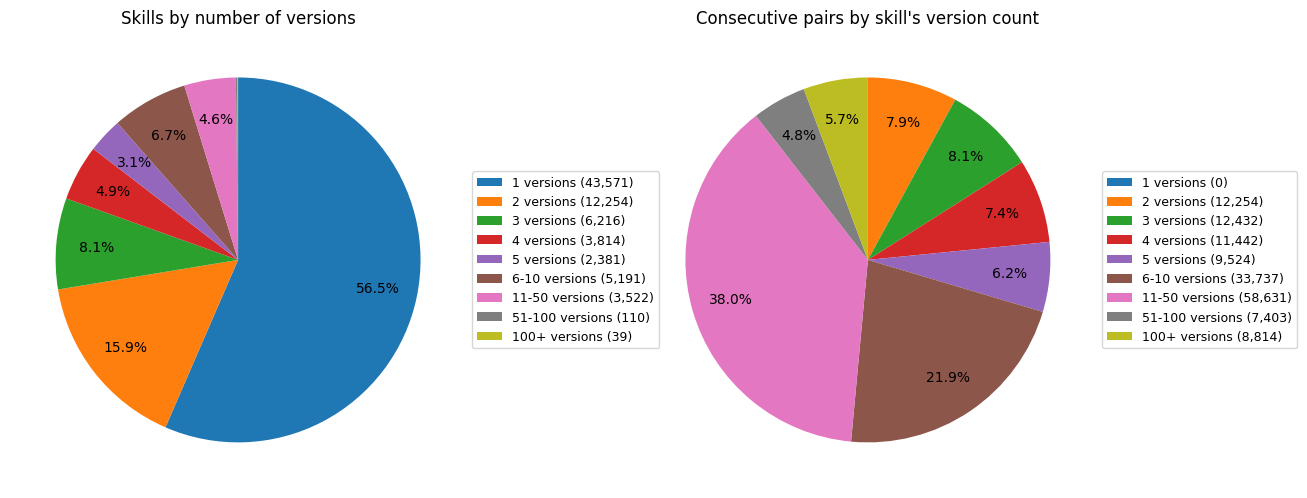

In [5]:
# Buckets of version counts: table + pie chart
bins   = [0, 1, 2, 3, 4, 5, 10, 50, 100, np.inf]
labels = ["1", "2", "3", "4", "5", "6-10", "11-50", "51-100", "100+"]
ok_counts["bucket"] = pd.cut(ok_counts["versions"], bins=bins, labels=labels)

bucket_tbl = ok_counts.groupby("bucket", observed=False).agg(
    skills=("versions", "size"),
    versions=("versions", "sum"),
)
bucket_tbl["pairs"] = (ok_counts.assign(p=ok_counts["versions"] - 1)
                       .groupby("bucket", observed=False)["p"].sum())
bucket_tbl["share_of_skills"] = (bucket_tbl["skills"] / bucket_tbl["skills"].sum()).map(pct)
bucket_tbl["share_of_pairs"] = (bucket_tbl["pairs"] / bucket_tbl["pairs"].sum()).map(pct)
display(bucket_tbl)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, col, title in [(axes[0], "skills", "Skills by number of versions"),
                       (axes[1], "pairs", "Consecutive pairs by skill's version count")]:
    vals = bucket_tbl[col]
    wedges, _, _ = ax.pie(vals, autopct=lambda x: f"{x:.1f}%" if x >= 2 else "",
                          startangle=90, counterclock=False, pctdistance=0.78)
    ax.set_title(title)
    ax.legend(wedges, [f"{l} versions ({n:,})" for l, n in zip(vals.index, vals)],
              loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)
plt.tight_layout()
plt.show()

In [6]:
# What each minimum-versions threshold keeps
total_pairs = int((v - 1).sum())
rows = []
for t in [2, 3, 4, 5, 10]:
    sel = v[v >= t]
    pairs_t = int((sel - 1).sum())
    rows.append({"threshold": f"{t}+ versions", "skills": len(sel), "pairs": pairs_t,
                 "share_of_all_pairs": pct(pairs_t / total_pairs),
                 "pairs_per_skill": round(pairs_t / len(sel), 1)})
display(pd.DataFrame(rows))

,threshold,skills,pairs,share_of_all_pairs,pairs_per_skill
0,2+ versions,33527,154237,100.0%,4.6
1,3+ versions,21273,141983,92.1%,6.7
2,4+ versions,15057,129551,84.0%,8.6
3,5+ versions,11243,118109,76.6%,10.5
4,10+ versions,4347,80932,52.5%,18.6


## 3. Stage 2a: version lists and changelogs

One record per candidate skill (2+ versions), holding the list of its versions with publish
time and changelog. Compared against Stage 1 to spot truncated lists.

The versions endpoint returns at most 50 versions per request. For skills with more than 50
versions, only the **50 most recent** are kept (approved by the instructor). For those skills,
`version_index = 1` is their oldest kept version, not their true first version.

In [7]:
version_lists_df = pd.read_json(VERSIONS_JSONL, lines=True, convert_dates=False)

print(f"{len(version_lists_df):,} skills in the file\n")
st = version_lists_df["status"].value_counts().rename("skills").to_frame()
st["share"] = (st["skills"] / len(version_lists_df)).map(pct)
display(st)

flat = []
for row in version_lists_df.itertuples():
    if row.status != "ok":
        continue
    for item in (row.items or []):
        flat.append({
            "skill_slug": row.skill_slug,
            "version": item.get("version"),
            "created_at": item.get("createdAt"),
            "changelog_text": item.get("changelog"),
            "changelog_source": item.get("changelogSource"),
        })
versions_flat_df = pd.DataFrame(flat)

returned = versions_flat_df.groupby("skill_slug").size().rename("returned")
expected = ok_counts.set_index("skill_slug")["versions"].rename("expected")
cmp = pd.concat([returned, expected], axis=1, join="inner")
cmp["missing"] = (cmp["expected"] - cmp["returned"]).clip(lower=0)
truncated = cmp[cmp["missing"] > 0]

published = pd.to_datetime(versions_flat_df["created_at"], unit="ms", utc=True)
cl = versions_flat_df["changelog_text"].fillna("").str.strip()

stats = pd.DataFrame([
    ("(skill, version) rows", f"{len(versions_flat_df):,}"),
    ("skills", f"{versions_flat_df['skill_slug'].nunique():,}"),
    ("earliest publish date", published.min().date()),
    ("latest publish date", published.max().date()),
    ("max versions returned for one skill", int(returned.max())),
    ("skills returning exactly 50 (page cap)", f"{int((returned == 50).sum()):,}"),
    ("skills with fewer versions than Stage 1 counted", f"{len(truncated):,}"),
    ("versions missing from those skills", f"{int(truncated['missing'].sum()):,}"),
    ("empty changelogs", f"{int((cl == '').sum()):,} ({pct((cl == '').mean())})"),
], columns=["stat", "value"])
display(stats)

src = versions_flat_df["changelog_source"].fillna("<missing>").value_counts().rename("versions").to_frame()
src["share"] = (src["versions"] / len(versions_flat_df)).map(pct)
print("changelog source (user = written by the author, auto = generated by the registry):")
display(src)

if len(truncated):
    print("most truncated skills:")
    display(truncated.sort_values("missing", ascending=False).head(10))

33,527 skills in the file



,skills,share
status,,
ok,33492,99.9%
failed_after_retries,32,0.1%
not_found,3,0.0%


,stat,value
0,"(skill, version) rows","177,339"
1,skills,"33,492"
2,earliest publish date,2026-01-04
3,latest publish date,2026-09-25
4,max versions returned for one skill,50
5,skills returning exactly 50 (page cap),152
6,skills with fewer versions than Stage 1 counted,613
7,versions missing from those skills,"10,417"
8,empty changelogs,15 (0.0%)


changelog source (user = written by the author, auto = generated by the registry):


,versions,share
changelog_source,,
user,127727,72.0%
auto,49579,28.0%
<missing>,33,0.0%


most truncated skills:


,returned,expected,missing
skill_slug,,,
onlyloveher/shield-cn,50,1294,1244
shenmeng/shenmeng-whale-alert-monitor,50,656,606
shenmeng/shenmeng-odds-movement-monitor,50,615,565
liyafeichina/write-a-skill,50,473,423
arberx/canonry,50,457,407
liuyanfeng1234/v19-trust-manifesto,50,280,230
wazionapps/nexo-brain,50,245,195
mnetfairy/ai-era-career-planner,50,242,192
mnetfairy/career-planner-china,50,237,187


In [8]:
# Paging attempt, for the record only. NOT used: the dataset keeps the latest 50
# versions of skills with more than 50 (instructor approved).
if PAGED_JSONL.exists():
    paged = pd.read_json(PAGED_JSONL, lines=True, convert_dates=False)
    paged["paged_count"] = paged["items"].map(len)
    paged = paged.merge(ok_counts[["skill_slug", "versions"]], on="skill_slug", how="left")
    paged["complete"] = paged["paged_count"] >= paged["versions"]
    print(f"{len(paged):,} skills re-crawled with paging, "
          f"{int(paged['complete'].sum()):,} now complete")
    display(paged["paged_count"].value_counts().sort_index().rename("skills").to_frame())
else:
    print("no paging file found")

152 skills re-crawled with paging, 5 now complete


,skills
paged_count,
50,149
100,2
150,1


## 4. Stage 2b: security record per version

The raw file is large (~830 MB), so it is streamed line by line and only the columns used
below are kept. "Present" means that scanner returned a status for the version.

Dates are **publish dates** of versions unless the column says "scan date". The newest version
of each skill is re-scanned with the current pipeline, which hides when a scanner was added,
so the table is shown twice: all versions, and older versions only (newest excluded).

In [8]:
KEEP = [
    "skill_slug", "version", "crawled_detail_status",
    "llm_normalized_status", "llm_model", "llm_checked_at",
    "crawled_skillspector_normalized_status", "crawled_skillspector_score",
    "crawled_skillspector_checked_at",
    "vt_normalized_status", "vt_source", "vt_checked_at",
]

rows = []
with SECURITY_JSONL.open(encoding="utf-8") as f:
    for line in f:
        if line.strip():
            r = json.loads(line)
            rows.append({k: r.get(k) for k in KEEP})
security_df = pd.DataFrame(rows, columns=KEEP)
del rows

print(f"{len(security_df):,} version records\n")
st = security_df["crawled_detail_status"].value_counts().rename("versions").to_frame()
st["share"] = (st["versions"] / len(security_df)).map(pct)
display(st)

177,339 version records



,versions,share
crawled_detail_status,,
ok,176659,99.6%
failed_after_retries,487,0.3%
not_found,193,0.1%


In [9]:
sec = (security_df[security_df["crawled_detail_status"] == "ok"]
       .merge(versions_flat_df[["skill_slug", "version", "created_at"]],
              on=["skill_slug", "version"], how="left"))
sec["published"] = ms_to_date(sec["created_at"])
sec["is_newest"] = sec["created_at"] == sec.groupby("skill_slug")["created_at"].transform("max")

SCANNERS = {
    # name: (column that says it is present, scan-date column)
    "LLM (ClawScan)": ("llm_normalized_status", "llm_checked_at"),
    "SkillSpector":   ("crawled_skillspector_score", "crawled_skillspector_checked_at"),
    "VirusTotal":     ("vt_normalized_status", "vt_checked_at"),
}

def coverage_table(frame):
    out = []
    for name, (col, ts) in SCANNERS.items():
        has = frame[col].notna()
        scan_dates = ms_to_date(frame.loc[has, ts].dropna())
        out.append({
            "scanner": name,
            "versions_with_it": int(has.sum()),
            "share": pct(has.mean()),
            "versions_without_it": int((~has).sum()),
            "earliest_publish_with": frame.loc[has, "published"].min(),
            "latest_publish_with": frame.loc[has, "published"].max(),
            "earliest_publish_without": frame.loc[~has, "published"].min(),
            "latest_publish_without": frame.loc[~has, "published"].max(),
            "earliest_scan_date": scan_dates.min() if len(scan_dates) else None,
            "latest_scan_date": scan_dates.max() if len(scan_dates) else None,
        })
    return pd.DataFrame(out).set_index("scanner").T

print(f"ALL successfully crawled versions ({len(sec):,}):")
display(coverage_table(sec))

older = sec[~sec["is_newest"]]
print(f"\nOLDER versions only, newest of each skill excluded ({len(older):,}):")
display(coverage_table(older))

ALL successfully crawled versions (176,659):


scanner,LLM (ClawScan),SkillSpector,VirusTotal
versions_with_it,171646,87150,114461
share,97.2%,49.3%,64.8%
versions_without_it,5013,89509,62198
earliest_publish_with,2026-01-04,2026-01-04,2026-01-04
latest_publish_with,2026-09-25,2026-09-25,2026-09-25
earliest_publish_without,2026-01-04,2026-01-04,2026-01-04
latest_publish_without,2026-05-13,2026-09-13,2026-09-25
earliest_scan_date,2026-02-10,2026-05-24,2026-02-06
latest_scan_date,2026-09-28,2026-09-28,2026-09-25



OLDER versions only, newest of each skill excluded (143,335):


scanner,LLM (ClawScan),SkillSpector,VirusTotal
versions_with_it,138329,54064,85530
share,96.5%,37.7%,59.7%
versions_without_it,5006,89271,57805
earliest_publish_with,2026-01-05,2026-01-17,2026-01-05
latest_publish_with,2026-09-25,2026-09-25,2026-09-25
earliest_publish_without,2026-01-04,2026-01-04,2026-01-04
latest_publish_without,2026-05-13,2026-09-13,2026-09-25
earliest_scan_date,2026-02-10,2026-05-24,2026-02-06
latest_scan_date,2026-09-25,2026-09-25,2026-09-25


,versions,llm,skillspector,virustotal
month,,,,
2026-01,1305,9.2%,0.5%,10.1%
2026-02,17580,78.5%,1.6%,43.3%
2026-03,41470,99.9%,1.1%,55.3%
2026-04,22880,100.0%,3.9%,68.0%
2026-05,12174,100.0%,38.3%,64.7%
2026-06,11210,100.0%,99.0%,81.6%
2026-07,13433,100.0%,99.5%,74.1%
2026-08,11084,100.0%,100.0%,59.7%
2026-09,12199,100.0%,99.9%,46.7%


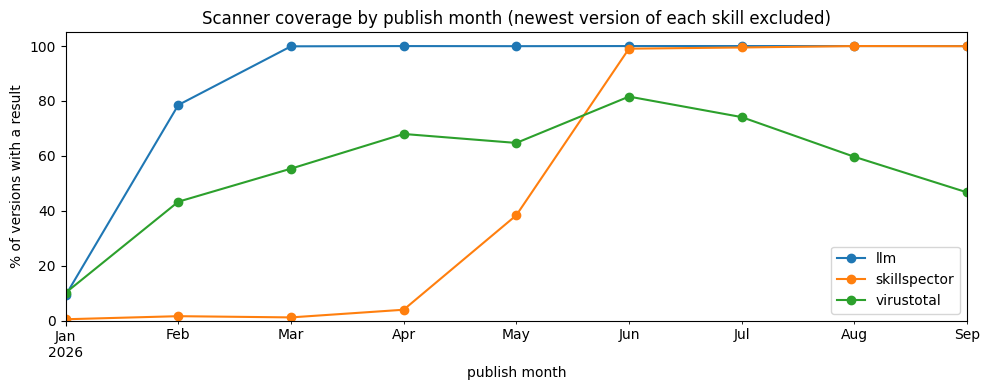

VirusTotal source (palm = model-based, engines = antivirus):


,versions
vt_source,
<no vt>,63053
engines,59341
palm,54265


In [10]:
# Coverage by publish month, older versions only (shows when each scanner came in)
older = older.assign(month=pd.to_datetime(older["created_at"], unit="ms").dt.to_period("M"))
monthly = older.groupby("month").agg(
    versions=("skill_slug", "size"),
    llm=("llm_normalized_status", lambda s: s.notna().mean()),
    skillspector=("crawled_skillspector_score", lambda s: s.notna().mean()),
    virustotal=("vt_normalized_status", lambda s: s.notna().mean()),
)
display(monthly.style.format({"llm": "{:.1%}", "skillspector": "{:.1%}", "virustotal": "{:.1%}"}))

ax = (monthly[["llm", "skillspector", "virustotal"]] * 100).plot(marker="o", figsize=(10, 4))
ax.set_ylabel("% of versions with a result")
ax.set_xlabel("publish month")
ax.set_title("Scanner coverage by publish month (newest version of each skill excluded)")
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

print("VirusTotal source (palm = model-based, engines = antivirus):")
display(sec["vt_source"].fillna("<no vt>").value_counts().rename("versions").to_frame())

## 5. The assembled dataset, diffs and content

`df` is the dataset: one row per (skill, version), crawled columns first, then the snapshot's
own 25 columns attached only to each skill's latest version.

In [11]:
df = pd.read_parquet(DATASET_PARQUET)
diffs_df = pd.read_parquet(DIFFS_PARQUET) if DIFFS_PARQUET.exists() else None
content_index = (pd.read_json(CONTENT_INDEX, lines=True, convert_dates=False)
                 if CONTENT_INDEX.exists() else None)
cached = len(list(CONTENT_DIR.rglob("*.json.gz"))) if CONTENT_DIR.exists() else 0

stats = [
    ("df rows", f"{len(df):,}"),
    ("df columns", len(df.columns)),
    ("df skills", f"{df['skill_slug'].nunique():,}"),
    ("rows carrying snapshot columns", f"{int(df['skill_version'].notna().sum()):,}"),
    ("content files cached", f"{cached:,} ({pct(cached / len(df))} of rows)"),
    ("content index rows", f"{len(content_index):,}" if content_index is not None else "none"),
]
if diffs_df is not None:
    has_diff = diffs_df["diff_text"].notna()
    stats += [
        ("diff rows", f"{len(diffs_df):,}"),
        ("rows with a diff vs previous", f"{int(has_diff.sum()):,}"),
        ("median lines changed", diffs_df["lines_changed"].median()),
        ("max lines changed", diffs_df["lines_changed"].max()),
    ]
display(pd.DataFrame(stats, columns=["stat", "value"]))

# Integrity: the parquet and the raw files should describe the same crawl
if len(df) == len(versions_flat_df):
    print("integrity: parquet row count matches the version lists")
else:
    print(f"WARNING: parquet has {len(df):,} rows but the version lists have {len(versions_flat_df):,}")

,stat,value
0,df rows,"177,339"
1,df columns,86
2,df skills,"33,492"
3,rows carrying snapshot columns,"33,479"
4,content files cached,304 (0.2% of rows)
5,content index rows,140
6,diff rows,304
7,rows with a diff vs previous,222
8,median lines changed,63.5
9,max lines changed,11484.0


integrity: parquet row count matches the version lists


## 6. Version pairs

A pair is a version compared against the one before it (by publish time), within the same skill.

A pair is **usable** when both sides were scanned. Without a scan on both sides there is no
label, so those pairs are dropped. That is the only exclusion.

Two kinds of pair are **kept and flagged** rather than dropped, so their effect can be tested later:

- `pipeline_changed`: the two sides went through different ClawHub scan pipelines
  (new = has SkillSpector, old = does not). `pipeline_transition` shows which way, e.g. `old -> new`.
- `model_changed`: the two sides were scanned by different LLM models.

Ratings from different pipelines or models may not be on the same scale. Keeping these pairs
for now lets us measure whether that matters instead of assuming it does.

In [12]:
p = df.sort_values(["skill_slug", "created_at"]).copy()

scanned = p["llm_normalized_status"].notna() | p["crawled_skillspector_score"].notna()
p["pipeline"] = np.where(~scanned, "unscanned",
                np.where(p["crawled_skillspector_score"].notna(), "new", "old"))
p["llm_model_filled"] = p["llm_model"].fillna("none")

for col in ["pipeline", "llm_model_filled", "version", "crawled_sha256",
            "llm_normalized_status", "crawled_skillspector_normalized_status",
            "changelog_text", "changelog_source"]:
    p[f"prev_{col}"] = p.groupby("skill_slug")[col].shift(1)
p["has_prev"] = p.groupby("skill_slug").cumcount() > 0

pairs = p[p["has_prev"]].copy()
both_scanned = (pairs["pipeline"] != "unscanned") & (pairs["prev_pipeline"] != "unscanned")

# Flags only, nothing excluded on these. Analyse them later.
pairs["pipeline_changed"] = pairs["pipeline"] != pairs["prev_pipeline"]
pairs["pipeline_transition"] = pairs["prev_pipeline"] + " -> " + pairs["pipeline"]
pairs["model_changed"] = pairs["llm_model_filled"] != pairs["prev_llm_model_filled"]

# Only rule: both sides need a scan, otherwise there is no label.
pairs["usable"] = both_scanned
usable_pairs = pairs[pairs["usable"]].copy()

total = len(pairs)
lost_unscanned = int((~both_scanned).sum())
funnel = pd.DataFrame([
    {"step": "all consecutive pairs", "lost": 0, "remaining": total},
    {"step": "minus: one side never scanned", "lost": lost_unscanned,
     "remaining": total - lost_unscanned},
])
funnel["remaining_share"] = (funnel["remaining"] / total).map(pct)
display(funnel)

n = len(usable_pairs)
print(f"usable pairs: {n:,} across {usable_pairs['skill_slug'].nunique():,} skills")
for flag, label in [("pipeline_changed", "crossed the pipeline change"),
                    ("model_changed", "scanned by different LLM models")]:
    k = int(usable_pairs[flag].sum())
    print(f"  {label:<32} {k:,} ({pct(k / n)})  kept, flagged")

print("\npipeline change x model change (usable pairs):")
display(pd.crosstab(usable_pairs["pipeline_changed"], usable_pairs["model_changed"],
                    rownames=["pipeline changed"], colnames=["model changed"],
                    margins=True, margins_name="total"))

print("pipeline transitions (previous -> this):")
t = usable_pairs["pipeline_transition"].value_counts().rename("pairs").to_frame()
t["share"] = (t["pairs"] / n).map(pct)
display(t)

print("model changes (previous -> this):")
mc = usable_pairs[usable_pairs["model_changed"]]
display((mc["prev_llm_model_filled"] + " -> " + mc["llm_model_filled"])
        .value_counts().rename("pairs").to_frame())

,step,lost,remaining,remaining_share
0,all consecutive pairs,0,143847,100.0%
1,minus: one side never scanned,5588,138259,96.1%


usable pairs: 138,259 across 32,025 skills
  crossed the pipeline change      22,050 (15.9%)  kept, flagged
  scanned by different LLM models  30,403 (22.0%)  kept, flagged

pipeline change x model change (usable pairs):


model changed,False,True,total
pipeline changed,,,
False,106344,9865,116209
True,1512,20538,22050
total,107856,30403,138259


pipeline transitions (previous -> this):


,pairs,share
pipeline_transition,,
old -> old,62420,45.1%
new -> new,53789,38.9%
old -> new,21783,15.8%
new -> old,267,0.2%


model changes (previous -> this):


,pairs
gpt-5-mini -> none,17257
gpt-5.5 -> none,10303
gpt-5-mini -> gpt-5.5,2539
none -> gpt-5.5,133
none -> gpt-5-mini,54
gpt-5.5 -> codex-security-worker,52
codex-security-worker -> gpt-5.5,40
codex-security-worker -> none,18
gpt-4.1-mini -> none,3
gpt-5.5 -> gpt-5-mini,2


## 7. Status transitions between consecutive versions

How the security status moves from the previous version to this one, over usable pairs.

- **stayed clean**: clean -> clean
- **introduced**: clean -> suspicious or malicious
- **fixed**: suspicious or malicious -> clean
- **stayed flagged**: suspicious/malicious -> suspicious/malicious
- **other**: anything involving a missing, pending or error status

Each scanner gets four views: every transition, a previous x current matrix, the grouped
counts, and the grouped counts split by pipeline transition and by model change.

The split tables show both counts and shares within each column. If, for example,
`old -> new` pairs show a much higher "introduced" rate than `old -> old`, the pipeline change
itself is moving the label and those pairs need separate handling.

Shown for the LLM (ClawScan) status on all usable pairs, then for SkillSpector. SkillSpector
only exists on the new pipeline, so its table only covers pairs where both sides have it.

In [13]:
FLAGGED = {"suspicious", "malicious"}
ORDER = ["stayed clean", "introduced", "fixed", "stayed flagged", "other"]

def transition_type(prev, curr):
    if prev == "clean" and curr == "clean":
        return "stayed clean"
    if prev == "clean" and curr in FLAGGED:
        return "introduced"
    if prev in FLAGGED and curr == "clean":
        return "fixed"
    if prev in FLAGGED and curr in FLAGGED:
        return "stayed flagged"
    return "other"

def transition_tables(frame, prev_col, curr_col, label):
    prev = frame[prev_col].fillna("missing")
    curr = frame[curr_col].fillna("missing")
    n = len(frame)
    print(f"=== {label}: {n:,} pairs ===\n")

    t = (prev + " -> " + curr).value_counts().rename("pairs").to_frame()
    t["share"] = (t["pairs"] / n).map(pct)
    print("every transition:")
    display(t)

    print("matrix (rows = previous version, columns = this version):")
    display(pd.crosstab(prev, curr, rownames=["previous"], colnames=["this"],
                        margins=True, margins_name="total"))

    types = pd.Series([transition_type(a, b) for a, b in zip(prev, curr)],
                      index=frame.index, name="type")
    summary = types.value_counts().reindex(ORDER, fill_value=0).rename("pairs").to_frame()
    summary["share"] = (summary["pairs"] / n).map(pct)
    print("grouped:")
    display(summary)

    for flag_col, title in [("pipeline_transition", "by pipeline transition"),
                            ("model_changed", "by whether the LLM model changed")]:
        counts = pd.crosstab(types, frame[flag_col]).reindex(ORDER, fill_value=0)
        shares = counts.div(counts.sum(axis=0), axis=1)
        print(f"grouped, {title} (counts, then share within each column):")
        display(counts)
        display(shares.style.format("{:.1%}"))
    return types

usable_pairs["llm_transition"] = transition_tables(
    usable_pairs, "prev_llm_normalized_status", "llm_normalized_status", "LLM (ClawScan) status")

=== LLM (ClawScan) status: 138,259 pairs ===

every transition:


,pairs,share
clean -> clean,51973,37.6%
suspicious -> suspicious,49712,36.0%
clean -> suspicious,20509,14.8%
suspicious -> clean,15395,11.1%
error -> suspicious,204,0.1%
suspicious -> error,147,0.1%
error -> clean,113,0.1%
clean -> error,105,0.1%
malicious -> suspicious,32,0.0%
error -> error,25,0.0%


matrix (rows = previous version, columns = this version):


this,clean,error,malicious,suspicious,total
previous,,,,,
clean,51973,105,9,20509,72596
error,113,25,0,204,342
malicious,6,0,9,32,47
suspicious,15395,147,20,49712,65274
total,67487,277,38,70457,138259


grouped:


,pairs,share
type,,
stayed clean,51973,37.6%
introduced,20518,14.8%
fixed,15401,11.1%
stayed flagged,49773,36.0%
other,594,0.4%


... (2 outputs left out)

pipeline_transition,new -> new,new -> old,old -> new,old -> old
type,,,,
stayed clean,43.9%,27.3%,27.3%,35.7%
introduced,13.3%,4.9%,27.5%,11.8%
fixed,8.0%,21.3%,10.4%,14.0%
stayed flagged,34.8%,27.0%,34.2%,37.7%
other,0.0%,19.5%,0.6%,0.7%


grouped, by whether the LLM model changed (counts, then share within each column):


model_changed,False,True
type,,
stayed clean,42864,9109
introduced,11985,8533
fixed,12707,2694
stayed flagged,39886,9887
other,414,180


model_changed,False,True
type,,
stayed clean,39.7%,30.0%
introduced,11.1%,28.1%
fixed,11.8%,8.9%
stayed flagged,37.0%,32.5%
other,0.4%,0.6%


In [14]:
# SkillSpector only exists on the new pipeline, so only new/new pairs have it on both sides
ss_pairs = usable_pairs[(usable_pairs["pipeline"] == "new")
                        & usable_pairs["crawled_skillspector_normalized_status"].notna()
                        & usable_pairs["prev_crawled_skillspector_normalized_status"].notna()]
ss_types = transition_tables(ss_pairs, "prev_crawled_skillspector_normalized_status",
                             "crawled_skillspector_normalized_status", "SkillSpector status")
usable_pairs["skillspector_transition"] = ss_types.reindex(usable_pairs.index)

=== SkillSpector status: 53,830 pairs ===

every transition:


,pairs,share
suspicious -> suspicious,28733,53.4%
clean -> clean,13868,25.8%
clean -> suspicious,8174,15.2%
suspicious -> clean,3014,5.6%
error -> suspicious,39,0.1%
error -> clean,2,0.0%


matrix (rows = previous version, columns = this version):


this,clean,suspicious,total
previous,,,
clean,13868,8174,22042
error,2,39,41
suspicious,3014,28733,31747
total,16884,36946,53830


grouped:


,pairs,share
type,,
stayed clean,13868,25.8%
introduced,8174,15.2%
fixed,3014,5.6%
stayed flagged,28733,53.4%
other,41,0.1%


... (2 outputs left out)

pipeline_transition,new -> new,old -> new
type,,
stayed clean,25.8%,0.0%
introduced,15.2%,0.0%
fixed,5.6%,0.0%
stayed flagged,53.4%,0.0%
other,0.0%,100.0%


grouped, by whether the LLM model changed (counts, then share within each column):


model_changed,False,True
type,,
stayed clean,12252,1616
introduced,5077,3097
fixed,2766,248
stayed flagged,25156,3577
other,29,12


model_changed,False,True
type,,
stayed clean,27.1%,18.9%
introduced,11.2%,36.2%
fixed,6.1%,2.9%
stayed flagged,55.6%,41.8%
other,0.1%,0.1%


In [15]:
# Same-content check: pairs whose bundle hash did not change. Any status change here is
# scanner noise, not an effect of the change. (Likely ~0 rows if the hash covers version metadata.)
same_hash = usable_pairs["crawled_sha256"].notna() & \
            usable_pairs["crawled_sha256"].eq(usable_pairs["prev_crawled_sha256"])
print(f"usable pairs with identical bundle hash: {int(same_hash.sum()):,}")
if same_hash.any():
    display(usable_pairs.loc[same_hash, "llm_transition"].value_counts().rename("pairs").to_frame())

usable pairs with identical bundle hash: 0


## 8. RQ1 sample frame

RQ1 asks which kinds of change introduce or fix security issues. Coders read the **diff**
between the two versions, with the changelog as context. So a pair qualifies when both sides
were scanned (section 6) and the skill's `SKILL.md` is in English, since that is what coders read.

Language belongs to the skill, so it is checked once per skill, on the `SKILL.md` in the frozen
snapshot (each skill's latest version). Dropping a skill before or after forming pairs gives the
same frame. It is done here and not in section 6 so that `pairs` and `usable_pairs` stay complete
for RQ2: the JIT model does not need English text.

Changelog language is no longer a filter. It is kept as a flag (`changelog_script`).

`changelog_source` marks who wrote the changelog:

- `user`: written by the author
- `auto`: generated by the registry

The sampling frame is saved at the very end of this section.

In [16]:
usable_pairs["has_changelog"] = usable_pairs["changelog_text"].fillna("").str.strip().ne("")

rq1_frame = usable_pairs[usable_pairs["has_changelog"]].copy()

n_u = len(usable_pairs)
print(f"usable pairs              {n_u:,}")
print(f"  with a changelog        {len(rq1_frame):,} ({pct(len(rq1_frame) / n_u)})")
print(f"  across skills           {rq1_frame['skill_slug'].nunique():,}")

print("\nchangelog source in the frame:")
src = rq1_frame["changelog_source"].fillna("<missing>").value_counts().rename("pairs").to_frame()
src["share"] = (src["pairs"] / len(rq1_frame)).map(pct)
display(src)

print("LLM transition type by changelog source (counts, then share within each column):")
counts = pd.crosstab(rq1_frame["llm_transition"], rq1_frame["changelog_source"],
                     margins=True, margins_name="total").reindex(ORDER + ["total"], fill_value=0)
display(counts)
shares = counts.drop(index="total").div(counts.drop(index="total").sum(axis=0), axis=1)
display(shares.style.format("{:.1%}"))

print("flags carried on the frame: pipeline_changed, model_changed, changelog_source")

print("\nsample of the frame:")
print(rq1_frame[["skill_slug", "prev_version", "version", "changelog_source",
                 "llm_transition", "changelog_text"]]
      .head(5).to_string(index=False, max_colwidth=60))

usable pairs              138,259
  with a changelog        138,259 (100.0%)
  across skills           32,025

changelog source in the frame:


,pairs,share
changelog_source,,
user,101874,73.7%
auto,36385,26.3%


LLM transition type by changelog source (counts, then share within each column):


changelog_source,auto,user,total
llm_transition,,,
stayed clean,13722,38251,51973
introduced,4621,15897,20518
fixed,3661,11740,15401
stayed flagged,14216,35557,49773
other,165,429,594
total,36385,101874,138259


changelog_source,auto,user,total
llm_transition,,,
stayed clean,37.7%,37.5%,37.6%
introduced,12.7%,15.6%,14.8%
fixed,10.1%,11.5%,11.1%
stayed flagged,39.1%,34.9%,36.0%
other,0.5%,0.4%,0.4%


flags carried on the frame: pipeline_changed, model_changed, changelog_source

sample of the frame:
          skill_slug prev_version version changelog_source llm_transition                                               changelog_text
000wonderclaw/clawcv        1.0.0   1.0.2             user          fixed - Added English README file (README_EN.md) for internatio...
000wonderclaw/clawcv        1.0.2   1.1.0             user     introduced ClawCV 1.1.0 introduces campus recruitment job matching a...
    00xmorty/conatus        1.0.0   1.0.1             user     introduced                                   Fix: republish to registry
     05u/jiuwu-agent        1.0.0   1.0.1             user stayed flagged - Added scripts/requirements.txt to manage Python depende...
   05u/jiuwu-message        1.0.0   1.0.1             user stayed flagged - Added initial scripts and requirements files for the sk...


### SKILL.md language

Checked on the prose a reader sees: the frontmatter `description` plus the body, with code blocks,
inline code and links removed.

- At least half of that prose is Chinese, Japanese or Korean characters, or Cyrillic or Arabic
  letters (one CJK character counts as one word): `non-latin`.
- Otherwise `langdetect` decides, on the first 3,000 characters.
- Fewer than 20 words of prose: `too short`. No `SKILL.md` in the snapshot: `missing`.

Limit: this uses each skill's latest `SKILL.md`. A skill that changed language between versions
(rare, e.g. translated to English later) is judged by its latest version.

The changelog flag (`changelog_script`) comes from the characters alone, so it is fast and needs
no detector. It only reports how many kept pairs have a non-Latin changelog.

In [17]:
import re
from langdetect import detect, DetectorFactory
from tqdm.auto import tqdm
DetectorFactory.seed = 0

FRONT = re.compile(r"\A\s*---(.*?)\n---\s*\n", re.S)
CODE_BLOCK = re.compile(r"```.*?```", re.S)
NONLATIN = re.compile(r"[一-鿿぀-ヿ가-힯Ѐ-ӿ؀-ۿ]")
LATIN_WORD = re.compile(r"[A-Za-z]{2,}")
MIN_WORDS = 20

def md_prose(md):
    """What a reader sees: frontmatter description + body, without code, inline code or links."""
    m = FRONT.match(md)
    desc = ""
    if m:
        d = re.search(r"description:\s*(.*)", m.group(1))
        desc, md = (d.group(1) if d else ""), md[m.end():]
    body = desc + "\n" + CODE_BLOCK.sub(" ", md)
    return re.sub(r"`[^`]*`|https?://\S+|\[[^\]]*\]\([^)]*\)", " ", body)

def md_lang(md):
    """(language, share of non-Latin script in the prose)"""
    if not isinstance(md, str) or not md.strip():
        return "missing", None
    prose = md_prose(md)
    nl, lw = len(NONLATIN.findall(prose)), len(LATIN_WORD.findall(prose))
    if nl + lw < MIN_WORDS:
        return "too short", None
    share = nl / (nl + lw)                 # one CJK character is about one English word
    if share >= 0.5:
        return "non-latin", share
    try:
        return detect(prose[:3000]), share
    except Exception:
        return "unknown", share

# One SKILL.md per skill: the snapshot's latest version
if df_all is not None:
    md_src = df_all[["skill_slug", "skill_md_content"]]
else:   # snapshot not downloaded: the same column sits on each skill's latest row in df
    md_src = df.loc[df["skill_version"].notna(), ["skill_slug", "skill_md_content"]]
md_src = md_src.drop_duplicates("skill_slug")
md_src = md_src[md_src["skill_slug"].isin(rq1_frame["skill_slug"])].copy()

res = [md_lang(t) for t in tqdm(md_src["skill_md_content"], desc="SKILL.md language")]
md_src["skill_md_lang"] = [r[0] for r in res]
md_src["skill_md_nonlatin_share"] = [r[1] for r in res]

rq1_frame = (rq1_frame.drop(columns=["skill_md_lang", "skill_md_nonlatin_share"], errors="ignore")
             .merge(md_src[["skill_slug", "skill_md_lang", "skill_md_nonlatin_share"]],
                    on="skill_slug", how="left"))
rq1_frame["skill_md_lang"] = rq1_frame["skill_md_lang"].fillna("missing")   # skill not in the snapshot

# Changelog: flag only, from the characters (fast, no detector)
CL_SCRIPTS = {"Chinese/Japanese": r"[一-鿿぀-ヿ]", "Korean": r"[가-힯]",
              "Cyrillic": r"[Ѐ-ӿ]", "Arabic/Urdu": r"[؀-ۿ]"}

def script_of(text):
    for name, pattern in CL_SCRIPTS.items():
        if re.search(pattern, text):
            return name
    return "Latin/other"

rq1_frame["changelog_script"] = rq1_frame["changelog_text"].fillna("").map(script_of)
print(f"{len(md_src):,} skills checked, {len(rq1_frame):,} pairs")

SKILL.md language:   0%|          | 0/32025 [00:00<?, ?it/s]

32,025 skills checked, 138,259 pairs


In [18]:
n = len(rq1_frame)
print("SKILL.md language, per skill and per pair:")
by = (md_src["skill_md_lang"].value_counts().rename("skills").to_frame()
      .join(rq1_frame["skill_md_lang"].value_counts().rename("pairs"), how="outer")
      .fillna(0).astype(int).sort_values("pairs", ascending=False))
by["share_of_pairs"] = (by["pairs"] / n).map(pct)
display(by.head(15))

def md_group(lang):
    if lang == "en":
        return "English"
    if lang in ("too short", "missing", "unknown"):
        return lang
    return "non-English"

print("SKILL.md language vs changelog script (pairs).")
print("Shows what the old changelog filter got wrong: non-English skills with Latin-script")
print("changelogs, and English skills with non-Latin changelogs.")
display(pd.crosstab(rq1_frame["skill_md_lang"].map(md_group), rq1_frame["changelog_script"],
                    rownames=["SKILL.md"], margins=True, margins_name="total"))

print("English SKILL.md share by LLM transition (share within each column):")
display(pd.crosstab(rq1_frame["skill_md_lang"].eq("en"), rq1_frame["llm_transition"],
                    normalize="columns").reindex(columns=ORDER).style.format("{:.1%}"))

SKILL.md language, per skill and per pair:


,skills,pairs,share_of_pairs
skill_md_lang,,,
en,21726,93388,67.5%
non-latin,10056,44221,32.0%
es,74,113,0.1%
id,32,103,0.1%
too short,26,89,0.1%
pt,27,67,0.0%
de,21,51,0.0%
da,4,44,0.0%
vi,18,41,0.0%


SKILL.md language vs changelog script (pairs).
Shows what the old changelog filter got wrong: non-English skills with Latin-script
changelogs, and English skills with non-Latin changelogs.


changelog_script,Arabic/Urdu,Chinese/Japanese,Cyrillic,Korean,Latin/other,total
SKILL.md,,,,,,
English,1,3427,32,31,89897,93388
missing,0,0,0,0,9,9
non-English,3,23365,37,102,21266,44773
too short,0,26,0,0,63,89
total,4,26818,69,133,111235,138259


English SKILL.md share by LLM transition (share within each column):


llm_transition,stayed clean,introduced,fixed,stayed flagged,other
skill_md_lang,,,,,
False,26.0%,30.0%,30.1%,40.8%,35.5%
True,74.0%,70.0%,69.9%,59.2%,64.5%


### Keep English SKILL.md only

Pairs whose skill has a non-English `SKILL.md` are removed from the RQ1 frame.

- `too short` (mostly code or frontmatter) is kept by default; check a few below.
- `missing` (no `SKILL.md` in the snapshot) is dropped by default, since its language cannot be checked.
- `langdetect` can mislabel technical English as another Latin-script language. The spot-check
  below prints a few of each; add a language to `KEEP_MISDETECTED` if they turn out to be English.

Report the before/after counts and transition shares in the methods section.

In [19]:
# Spot-check: Latin-script SKILL.md detected as another language, plus 'too short' and 'missing'
langs = [l for l in md_src["skill_md_lang"].value_counts().index if l not in ("en", "non-latin")]
for lang in langs[:12]:
    sub = md_src[md_src["skill_md_lang"] == lang]
    print(f"\n=== {lang} ({len(sub):,} skills) ===")
    for slug, t in sub[["skill_slug", "skill_md_content"]].sample(min(3, len(sub)), random_state=0).itertuples(index=False):
        prose = " ".join(md_prose(t).split())[:160] if isinstance(t, str) else "<no SKILL.md>"
        print(f"- {slug}: {prose}")


=== es (74 skills) ===
- formula100k/calendarizador-urgencias-formula100k: "Construye el CALENDARIO DE RAZONES DE URGENCIA (mensual + pool semanal) de cualquier producto/programa/servicio con la metodología de urgencia honesta de FÓRMU
- formula100k/clonador-carrusel-formula100k: "Skill ESPEJO de FÓRMULA 100K. Toma una CAPTURA DE PANTALLA o un ENLACE de Instagram/TikTok del carrusel de cualquier referente, extrae el \"ADN de estilo\" (la
- formula100k/broll-vsl-formula100k: "Genera entre 15-25 clips de B-roll cinematográficos para VSL o videos largos usando Higgsfield Seedance 2.0 y Cinema Studio 3.0. Regla 80/20: 80% de los clips 

=== id (32 skills) ===
- pmuhammadagus-byte/test-driven-development: "Gunakan saat membuat fitur baru, bug fix, refactoring, atau perubahan behavior—dengan menulis test dulu, lihat gagal, lalu tulis kode minimal untuk lewat. Akti
- pmuhammadagus-byte/brain-core-ultra: "Gunakan saat user minta reasoning mendalam sebelum bertindak pada task kompleks berdepen

In [20]:
KEEP_TOO_SHORT = True       # little prose (mostly code or frontmatter); see the spot-check
KEEP_MISSING = False        # no SKILL.md in the snapshot, language cannot be checked
KEEP_MISDETECTED = []       # e.g. ["sl", "ca"] if the spot-check shows those are really English

keep_langs = {"en"} | set(KEEP_MISDETECTED)
if KEEP_TOO_SHORT:
    keep_langs.add("too short")
if KEEP_MISSING:
    keep_langs.add("missing")

before = rq1_frame
keep = before["skill_md_lang"].isin(keep_langs)
rq1_frame = before[keep].copy()

removed = len(before) - len(rq1_frame)
print(f"kept SKILL.md languages: {sorted(keep_langs)}")
print(f"before {len(before):,} pairs, after {len(rq1_frame):,} "
      f"({removed:,} removed, {pct(removed / len(before))})")
print(f"skills before {before['skill_slug'].nunique():,}, after {rq1_frame['skill_slug'].nunique():,}")

print("\nremoved, by SKILL.md language:")
display(before.loc[~keep, "skill_md_lang"].value_counts().head(10).rename("pairs").to_frame())

print("LLM transition share, before vs after:")
cmp = pd.concat([before["llm_transition"].value_counts(normalize=True).rename("before"),
                 rq1_frame["llm_transition"].value_counts(normalize=True).rename("after")],
                axis=1).reindex(ORDER)
display(cmp.style.format("{:.1%}"))

print("changelog source share, before vs after:")
cmp = pd.concat([before["changelog_source"].value_counts(normalize=True).rename("before"),
                 rq1_frame["changelog_source"].value_counts(normalize=True).rename("after")],
                axis=1)
display(cmp.style.format("{:.1%}"))

print("changelog script in the kept pairs (flag only, not filtered):")
cs = rq1_frame["changelog_script"].value_counts().rename("pairs").to_frame()
cs["share"] = (cs["pairs"] / len(rq1_frame)).map(pct)
display(cs)
del before

kept SKILL.md languages: ['en', 'too short']
before 138,259 pairs, after 93,477 (44,782 removed, 32.4%)
skills before 32,025, after 21,752

removed, by SKILL.md language:


,pairs
skill_md_lang,
non-latin,44221
es,113
id,103
pt,67
de,51
da,44
vi,41
it,36
pl,26


LLM transition share, before vs after:


,before,after
llm_transition,,
stayed clean,37.6%,41.2%
introduced,14.8%,15.4%
fixed,11.1%,11.5%
stayed flagged,36.0%,31.5%
other,0.4%,0.4%


changelog source share, before vs after:


,before,after
changelog_source,,
user,73.7%,73.6%
auto,26.3%,26.4%


changelog script in the kept pairs (flag only, not filtered):


,pairs,share
changelog_script,,
Latin/other,89960,96.2%
Chinese/Japanese,3453,3.7%
Cyrillic,32,0.0%
Korean,31,0.0%
Arabic/Urdu,1,0.0%


### Save the sampling frame

Written last, so `rq1_frame.parquet` holds only the pairs that passed every filter above.
Any sample drawn from an earlier version of this file should be discarded.

In [21]:
# Save the sampling frame for rq1_sampling.ipynb (slim columns only)
SAVE_COLS = ["skill_slug", "prev_version", "version", "changelog_source", "changelog_text",
             "changelog_script", "skill_md_lang", "skill_md_nonlatin_share",
             "llm_transition", "pipeline_transition", "pipeline_changed", "model_changed"]
rq1_frame[SAVE_COLS].to_parquet("rq1_frame.parquet", index=False)
print(f"saved rq1_frame.parquet: {len(rq1_frame):,} pairs across "
      f"{rq1_frame['skill_slug'].nunique():,} skills")

saved rq1_frame.parquet: 93,477 pairs across 21,752 skills


## 9. Ready

| name | what it is |
|---|---|
| `df_all` | frozen Hugging Face snapshot, 77,873 skills at latest version |
| `counts_df` / `ok_counts` | Stage 1 version counts per skill |
| `versions_flat_df` | Stage 2a, one row per (skill, version) with changelog, latest 50 versions max |
| `security_df` | Stage 2b, slim per-version scanner columns |
| `df` | assembled dataset, one row per (skill, version) |
| `diffs_df` | line-level diffs, pilot coverage only |
| `pairs` | every consecutive version pair |
| `usable_pairs` | both sides scanned (pipeline and model changes kept, see the flags); also the RQ2 base |
| `md_src` | one row per RQ1 skill with its SKILL.md language |
| `rq1_frame` | usable pairs whose skill has an English SKILL.md, saved to `rq1_frame.parquet` |

Next: open `rq1_sampling.ipynb`. Rounds already drawn stay as they are; draw new rounds and
Phase 2 from the new `rq1_frame.parquet`.